In [1]:
import sys
from pathlib import Path
_here = Path.cwd().resolve()
for _p in [_here, _here / "notebooks", _here.parent]:
    if (_p / "_nb_common.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
        break
import _nb_common as nb
nb.style()
rng = nb.set_seed()
nb.env_report()


NB_ENV_JSON:{"cryptography": "46.0.7", "cwd": "/Users/guykaptue/Downloads/insurance_federated_learning/notebooks", "dp_accounting": null, "executable": "/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python", "flwr": "1.31.0", "matplotlib": "3.11.1", "mode": "light", "networkx": "3.6.1", "numpy": "1.26.4", "pandas": "2.2.3", "pgmpy": "0.1.26", "platform": "macOS-26.5.1-arm64-arm-64bit", "plotly": "5.24.1", "python": "3.11.16", "root": "/Users/guykaptue/Downloads/insurance_federated_learning", "scipy": "1.17.1", "seaborn": "0.13.2", "seed": 42, "sklearn": "1.5.2", "statsmodels": "0.14.6", "torch": "2.4.1"}


{'python': '3.11.16',
 'executable': '/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python',
 'platform': 'macOS-26.5.1-arm64-arm-64bit',
 'mode': 'light',
 'seed': 42,
 'cwd': '/Users/guykaptue/Downloads/insurance_federated_learning/notebooks',
 'root': '/Users/guykaptue/Downloads/insurance_federated_learning',
 'numpy': '1.26.4',
 'pandas': '2.2.3',
 'scipy': '1.17.1',
 'sklearn': '1.5.2',
 'matplotlib': '3.11.1',
 'plotly': '5.24.1',
 'seaborn': '0.13.2',
 'torch': '2.4.1',
 'flwr': '1.31.0',
 'dp_accounting': None,
 'networkx': '3.6.1',
 'statsmodels': '0.14.6',
 'pgmpy': '0.1.26',
 'cryptography': '46.0.7'}

# Causal Inference Quickstart: DAG, Backdoor Adjustment, and DR/AIPW

**Purpose.** Demonstrate causal effect estimation on the project's federated insurance data using a declared DAG, adjustment set, and semi-synthetic truth injection for validation. We compare naive, backdoor-adjusted, and doubly robust (AIPW-style) estimates against an injected ground-truth ATE.

## Learning objectives
- Read and visualize the causal DAG and adjustment set from `docs/causal/dag.yaml`.
- Explain potential outcomes, ATE, backdoor criterion, and doubly robust estimation.
- Estimate effects with project causal APIs when available, or a clearly labeled fallback.
- Validate estimators against `inject_truth`/`ground_truth_ate` (semi-synthetic ground truth).
- Examine propensity overlap, covariate balance, and simple heterogeneity (CATE by strata).

## Background and math

### Potential outcomes and ATE
For treatment $T\in\{0,1\}$ and outcome $Y$, potential outcomes are $Y(1), Y(0)$. The average treatment effect:
$$
\mathrm{ATE} = \mathbb{E}[Y(1)-Y(0)].
$$
*Meaning here:* the average change in outcome (e.g. `claim_risk_score`) caused by treatment (e.g. `has_claims`), in the synthetic injected-truth setting.

### Backdoor criterion and adjustment
If a set $Z$ blocks all backdoor paths from $T$ to $Y$ in the DAG and contains no descendants of $T$, then under consistency/positivity,
$$
\mathrm{ATE}=\mathbb{E}_Z\left[\mathbb{E}[Y\mid T=1,Z]-\mathbb{E}[Y\mid T=0,Z]\right].
$$
*Meaning here:* adjusting for confounders $Z$ removes spurious associations.

### Doubly robust (AIPW) estimator
With propensity $e(Z)=P(T=1\mid Z)$ and outcome models $\mu_t(Z)=\mathbb{E}[Y\mid T=t,Z]$,
$$
\hat\tau_{DR}=\frac{1}{n}\sum_i\left[\mu_1(Z_i)-\mu_0(Z_i)+\frac{T_i(Y_i-\mu_1(Z_i))}{e(Z_i)}-\frac{(1-T_i)(Y_i-\mu_0(Z_i))}{1-e(Z_i)}\right].
$$
*Meaning here:* consistent if either outcome or propensity model is correctly specified (doubly robust), often with better efficiency.

## Assumptions and limitations
- `has_claims` as "treatment" and injected `claim_risk_score_true` are **demonstration constructs**. Recovery of injected truth tests estimator implementation, not real insurance causality.
- DAG/adjustment validity depends on domain assumptions encoded in `docs/causal/dag.yaml`.
- Positivity/overlap and model specification are required; light-mode samples increase uncertainty.


In [2]:
from dataclasses import dataclass
@dataclass(frozen=True)
class Cfg:
    seed: int = nb.SEED
    n_rows: int = 2000 if nb.MODE == "light" else 6000
    base_effect: float = 5.0
    n_boot: int = 80 if nb.MODE == "light" else 200
cfg = Cfg(); cfg


Cfg(seed=42, n_rows=2000, base_effect=5.0, n_boot=80)

In [3]:
import json, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import yaml
import statsmodels.api as sm
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Project truth injection (available without pgmpy)
from insurance_fl.causal.truth import inject_truth, ground_truth_ate

clients = nb.load_clients(split='train', n_max=cfg.n_rows)
df = pd.concat([v.assign(client=k) for k,v in clients.items()], ignore_index=True)
df = inject_truth(df, seed=cfg.seed, base_effect=cfg.base_effect)
if 'has_claims' not in df.columns and 'number_of_claims' in df.columns:
    df['has_claims'] = (df['number_of_claims'] > 0).astype(int)
TREAT = 'has_claims'
OUT_OBS = 'claim_risk_score'
OUT_TRUE = 'claim_risk_score_true'
Z = [c for c in ['age','annual_income','savings_balance','credit_score','debt_to_income_ratio'] if c in df.columns]
truth = ground_truth_ate(df)
print('rows:', len(df), 'truth ATE:', truth)
print('treatment rate:', df[TREAT].mean())


rows: 8000 truth ATE: 1.2276875
treatment rate: 0.2345


## DAG and adjustment set

In [4]:
dag_path = nb.ROOT / 'docs/causal/dag.yaml'
spec = yaml.safe_load(dag_path.read_text()) if dag_path.exists() else None
print('DAG path:', dag_path, 'exists:', dag_path.exists())
if spec:
    print('nodes:', len(spec.get('nodes',[])), 'edges:', len(spec.get('edges',[])))
    print('adjustment_sets keys:', list((spec.get('adjustment_sets') or {}).keys())[:5])
# Try project DAG validation (requires pgmpy)
dag_errors = None
try:
    from insurance_fl.causal.dag_check import validate_dag, build_pgmpy_dag, load_dag
    spec2 = load_dag(str(dag_path))
    dag_errors = validate_dag(spec2)
    print('project validate_dag errors:', dag_errors)
except Exception as e:
    print('[note] project DAG validation unavailable:', e)
    # lightweight structural checks
    dag_errors = []
    node_names = {n['name'] for n in spec.get('nodes',[])} if spec else set()
    for e in (spec.get('edges',[]) if spec else []):
        if e['source'] not in node_names or e['target'] not in node_names:
            dag_errors.append(f"bad edge {e}")
    print('fallback structural errors:', dag_errors)


DAG path: /Users/guykaptue/Downloads/insurance_federated_learning/docs/causal/dag.yaml exists: True
nodes: 42 edges: 46
adjustment_sets keys: ['has_claims__claim_risk_score']
project validate_dag errors: []


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/causal_dag.png


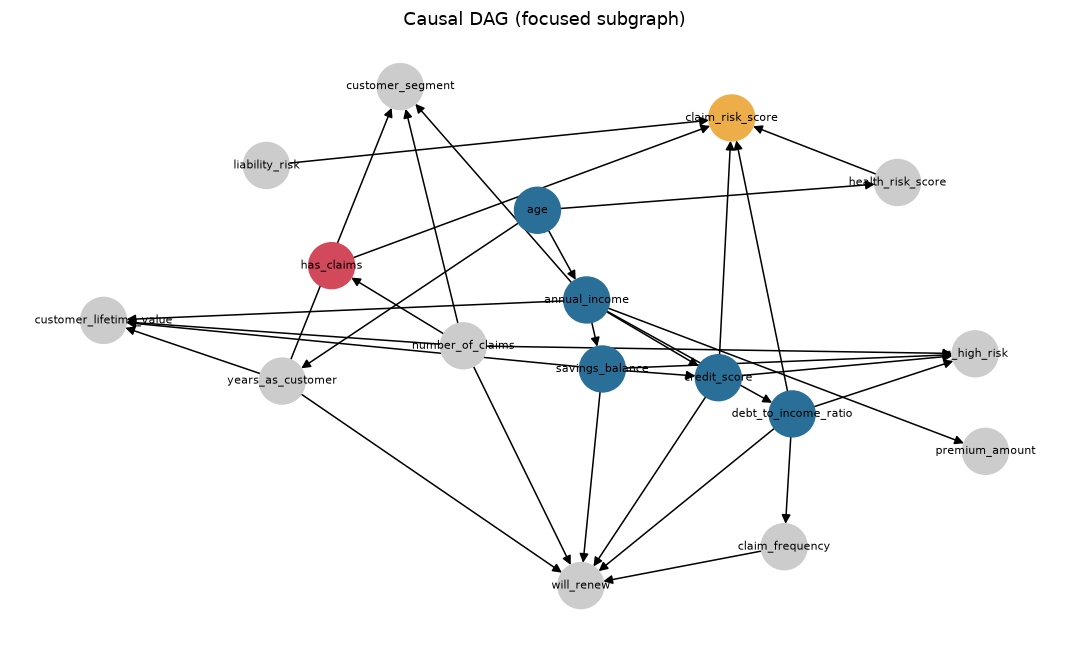

In [5]:
# Figure 1: DAG drawing (networkx if available, else schematic)
nx = nb.optional('networkx')
fig, ax = plt.subplots(figsize=(10,6))
if spec and nx is not None:
    G = nx.DiGraph()
    for e in spec.get('edges',[]):
        G.add_edge(e['source'], e['target'])
    # focus on relevant subgraph for readability
    focus = set(Z + [TREAT, OUT_OBS, 'claim_risk_score_true', 'country'])
    nodes = [n for n in G.nodes() if n in focus or G.degree(n)>1]
    H = G.subgraph(nodes).copy() if nodes else G
    pos = nx.spring_layout(H, seed=nb.SEED, k=1.2)
    colors = []
    for n in H.nodes():
        if n==TREAT: colors.append('#d1495b')
        elif n in [OUT_OBS, OUT_TRUE]: colors.append('#edae49')
        elif n in Z: colors.append('#2a6f97')
        else: colors.append('#cccccc')
    nx.draw(H, pos, with_labels=True, node_color=colors, node_size=900, font_size=7, arrowsize=12, ax=ax)
    ax.set_title('Causal DAG (focused subgraph)')
else:
    ax.axis('off')
    txt = 'DAG nodes/edges loaded from YAML\n' + '\n'.join([f"{e['source']} -> {e['target']} ({e.get('kind')})" for e in (spec.get('edges',[])[:20] if spec else [])])
    ax.text(0.01,0.99, txt, va='top', family='monospace', fontsize=8)
    ax.set_title('Causal DAG (text fallback)')
fig.tight_layout(); nb.save_fig(fig, 'causal_dag'); plt.show()


## Estimators: naive, backdoor, doubly robust (project API or fallback)

In [6]:
# Try project estimators (may require pgmpy); fallback to statsmodels/sklearn implementations
use_project = False
bd = dr = None
try:
    from insurance_fl.causal.estimands import CausalEstimand, estimate_backdoor, estimate_doubly_robust
    est = CausalEstimand.from_dag(
        name='has_claims__claim_risk_score', treatment=TREAT, outcome=OUT_OBS,
        adjustment_set=tuple(Z), dag_path=str(dag_path))
    bd = estimate_backdoor(df, est)
    dr = estimate_doubly_robust(df, est)
    use_project = True
    print('[project estimators] used insurance_fl.causal.estimands')
except Exception as e:
    print('[fallback estimators] project estimators unavailable:', e)

def backdoor_fallback(data, treat, outcome, zcols):
    d = data[[treat,outcome]+list(zcols)].dropna().copy()
    design_cols = [treat] + list(zcols)
    X = sm.add_constant(d[design_cols].astype(float), has_constant='add')
    model = sm.OLS(d[outcome].astype(float), X).fit()
    ate_coef = float(model.params.get(treat, np.nan))
    ci = model.conf_int().loc[treat].tolist() if treat in model.conf_int().index else [np.nan, np.nan]
    d1=d.copy(); d1[treat]=1.0
    d0=d.copy(); d0[treat]=0.0
    X1 = sm.add_constant(d1[design_cols].astype(float), has_constant='add').reindex(columns=X.columns, fill_value=0.0)
    X0 = sm.add_constant(d0[design_cols].astype(float), has_constant='add').reindex(columns=X.columns, fill_value=0.0)
    mu1 = model.predict(X1)
    mu0 = model.predict(X0)
    ate_g = float((np.asarray(mu1)-np.asarray(mu0)).mean())
    return {'ate': ate_g, 'coef_ate': ate_coef, 'ci_low': float(ci[0]), 'ci_high': float(ci[1]), 'n': int(len(d)), 'method': 'backdoor_ols_fallback'}

def aipw_fallback(data, treat, outcome, zcols, folds=5, seed=nb.SEED):
    d = data[[treat,outcome]+list(zcols)].dropna().reset_index(drop=True)
    t = d[treat].astype(float).values
    y = d[outcome].astype(float).values
    Zm = SimpleImputer(strategy='median').fit_transform(d[list(zcols)].values.astype(float))
    Zs = StandardScaler().fit_transform(Zm)
    kf = KFold(n_splits=folds, shuffle=True, random_state=seed)
    e = np.zeros(len(d)); mu0 = np.zeros(len(d)); mu1 = np.zeros(len(d))
    for tr, te in kf.split(Zs):
        ps = LogisticRegression(max_iter=400).fit(Zs[tr], t[tr])
        e[te] = np.clip(ps.predict_proba(Zs[te])[:,1], 0.01, 0.99)
        Zte_df = pd.DataFrame(Zs[te], columns=list(zcols))
        Xte = sm.add_constant(Zte_df, has_constant='add')
        for val, arr in [(0,mu0),(1,mu1)]:
            msk = t[tr]==val
            if msk.sum() < 5:
                arr[te] = y[tr].mean()
                continue
            Ztr_df = pd.DataFrame(Zs[tr][msk], columns=list(zcols))
            Xtr = sm.add_constant(Ztr_df, has_constant='add')
            om = sm.OLS(y[tr][msk], Xtr).fit()
            Xte_aligned = Xte.reindex(columns=om.params.index, fill_value=0.0)
            arr[te] = np.asarray(om.predict(Xte_aligned), dtype=float)
    terms = (mu1-mu0) + t*(y-mu1)/e - (1-t)*(y-mu0)/(1-e)
    ate = float(np.mean(terms)); se = float(np.std(terms, ddof=1)/np.sqrt(len(terms)))
    return {'ate': ate, 'ci_low': ate-1.96*se, 'ci_high': ate+1.96*se, 'n': int(len(d)), 'method': 'aipw_fallback'}

if not use_project:
    bd = backdoor_fallback(df, TREAT, OUT_OBS, Z)
    dr = aipw_fallback(df, TREAT, OUT_OBS, Z)
    print('fallback backdoor:', bd)
    print('fallback aipw:', dr)
else:
    print('backdoor:', bd)
    print('dr:', dr)


[project estimators] used insurance_fl.causal.estimands
backdoor: {'ate': 8.893188663856652, 'ci_low': 8.540971911538923, 'ci_high': 9.24540541617438, 'n': 6831, 'method': 'backdoor_glm', 'adjustment_set': ['age', 'annual_income', 'savings_balance', 'credit_score', 'debt_to_income_ratio']}
dr: {'ate': 8.784275744270564, 'ci_low': 8.329024429472934, 'ci_high': 9.239527059068195, 'n': 6831, 'method': 'aipw', 'adjustment_set': ['age', 'annual_income', 'savings_balance', 'credit_score', 'debt_to_income_ratio']}


In [7]:
# naive difference in means
d0 = df[[TREAT, OUT_OBS]].dropna()
naive = float(d0.loc[d0[TREAT]==1, OUT_OBS].mean() - d0.loc[d0[TREAT]==0, OUT_OBS].mean())
naive_true = float(df.loc[df[TREAT]==1, OUT_TRUE].mean() - df.loc[df[TREAT]==0, OUT_TRUE].mean())
est_table = pd.DataFrame([
    {'estimator': 'naive_diff_means_obs', 'ate': naive},
    {'estimator': 'backdoor_adjusted', 'ate': float(bd['ate']), 'ci_low': bd.get('ci_low'), 'ci_high': bd.get('ci_high')},
    {'estimator': 'doubly_robust_aipw', 'ate': float(dr['ate']), 'ci_low': dr.get('ci_low'), 'ci_high': dr.get('ci_high')},
    {'estimator': 'naive_diff_means_true', 'ate': naive_true},
    {'estimator': 'ground_truth_injected', 'ate': float(truth)},
])
est_table


,estimator,ate,ci_low,ci_high
0,naive_diff_means_obs,8.910316,NaN,NaN
1,backdoor_adjusted,8.893189,8.540972,9.245405
2,doubly_robust_aipw,8.784276,8.329024,9.239527
3,naive_diff_means_true,14.145657,NaN,NaN
4,ground_truth_injected,1.227688,NaN,NaN


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/causal_estimates.png


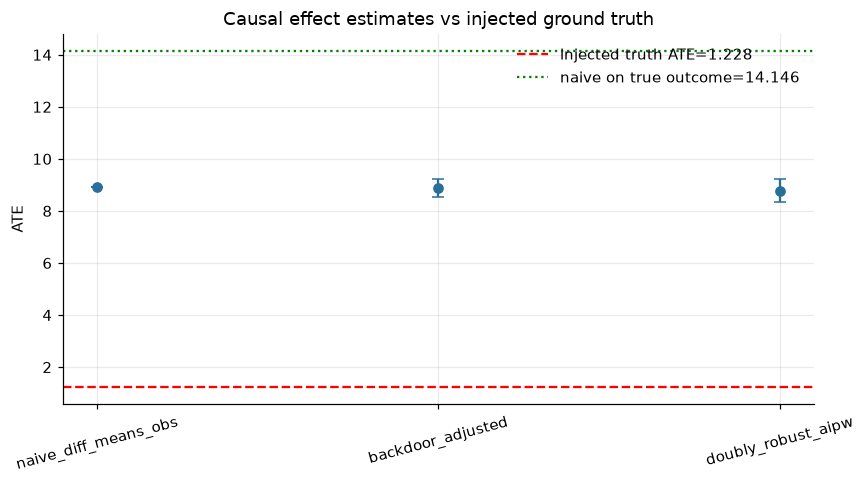

In [8]:
# Figure 2: estimates with CI and truth line
fig, ax = plt.subplots(figsize=(8,4.5))
plot_rows = est_table[est_table['estimator'].isin(['naive_diff_means_obs','backdoor_adjusted','doubly_robust_aipw'])]
x = np.arange(len(plot_rows))
ax.errorbar(x, plot_rows['ate'], yerr=[plot_rows['ate']-plot_rows['ci_low'].fillna(plot_rows['ate']), plot_rows['ci_high'].fillna(plot_rows['ate'])-plot_rows['ate']], fmt='o', capsize=4)
ax.set_xticks(x); ax.set_xticklabels(plot_rows['estimator'], rotation=15)
ax.axhline(truth, color='red', ls='--', label=f'injected truth ATE={truth:.3f}')
ax.axhline(naive_true, color='green', ls=':', label=f'naive on true outcome={naive_true:.3f}')
ax.set_title('Causal effect estimates vs injected ground truth'); ax.set_ylabel('ATE'); ax.legend()
fig.tight_layout(); nb.save_fig(fig, 'causal_estimates'); plt.show()


## Propensity scores, overlap, and covariate balance

In [9]:
# Propensity model P(T=1|Z)
d = df[[TREAT]+Z].dropna().copy()
Xm = SimpleImputer(strategy='median').fit_transform(d[Z].values)
Xs = StandardScaler().fit_transform(Xm)
ps_model = LogisticRegression(max_iter=500).fit(Xs, d[TREAT].values)
ps = np.clip(ps_model.predict_proba(Xs)[:,1], 1e-3, 1-1e-3)
d = d.assign(ps=ps)
# IPW weights for ATE
w_ate = np.where(d[TREAT]==1, 1/ps, 1/(1-ps))

def smd(x_t, x_c, w_t=None, w_c=None):
    if w_t is None:
        mt, vt = np.mean(x_t), np.var(x_t, ddof=1)
        mc, vc = np.mean(x_c), np.var(x_c, ddof=1)
    else:
        mt = np.average(x_t, weights=w_t); mc = np.average(x_c, weights=w_c)
        vt = np.average((x_t-mt)**2, weights=w_t); vc = np.average((x_c-mc)**2, weights=w_c)
    sp = np.sqrt((vt+vc)/2) or 1e-12
    return (mt-mc)/sp

bal_rows=[]
for col in Z:
    xt = d.loc[d[TREAT]==1,col].astype(float).values
    xc = d.loc[d[TREAT]==0,col].astype(float).values
    Xcol = d[col].astype(float).values
    # unweighted
    bal_rows.append({'covariate':col,'stage':'before','smd': smd(d.loc[d[TREAT]==1,col].values, d.loc[d[TREAT]==0,col].values)})
    # weighted (stabilized-like simple)
    wt = w_ate[d[TREAT]==1]; wc = w_ate[d[TREAT]==0]
    bal_rows.append({'covariate':col,'stage':'after_ipw','smd': smd(d.loc[d[TREAT]==1,col].values, d.loc[d[TREAT]==0,col].values, wt, wc)})
bal = pd.DataFrame(bal_rows)
bal.head()


,covariate,stage,smd
0,age,before,-0.034889
1,age,after_ipw,-0.001684
2,annual_income,before,-0.089814
3,annual_income,after_ipw,-0.004772
4,savings_balance,before,-0.060534


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/causal_propensity_balance.png


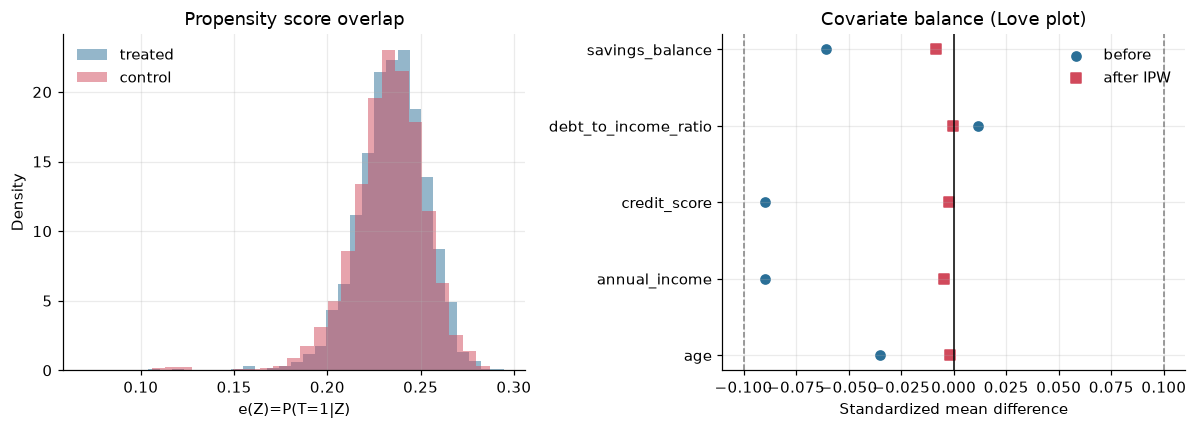

In [10]:
# Figure 3: propensity overlap and love plot
fig, axes = plt.subplots(1,2, figsize=(11,4))
axes[0].hist(d.loc[d[TREAT]==1,'ps'], bins=30, alpha=0.5, density=True, label='treated')
axes[0].hist(d.loc[d[TREAT]==0,'ps'], bins=30, alpha=0.5, density=True, label='control')
axes[0].set_title('Propensity score overlap'); axes[0].set_xlabel('e(Z)=P(T=1|Z)'); axes[0].set_ylabel('Density'); axes[0].legend()
# love plot
pv = bal.pivot(index='covariate', columns='stage', values='smd')
pv = pv.reindex(columns=['before','after_ipw'])
ypos = np.arange(len(pv))
axes[1].axvline(0, color='k', lw=1)
axes[1].axvline(0.1, color='gray', ls='--', lw=1); axes[1].axvline(-0.1, color='gray', ls='--', lw=1)
axes[1].scatter(pv['before'], ypos, label='before', marker='o')
axes[1].scatter(pv['after_ipw'], ypos, label='after IPW', marker='s')
axes[1].set_yticks(ypos); axes[1].set_yticklabels(pv.index)
axes[1].set_title('Covariate balance (Love plot)'); axes[1].set_xlabel('Standardized mean difference'); axes[1].legend()
fig.tight_layout(); nb.save_fig(fig, 'causal_propensity_balance'); plt.show()


## Sensitivity and heterogeneity (CATE by strata)

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/causal_sensitivity.png


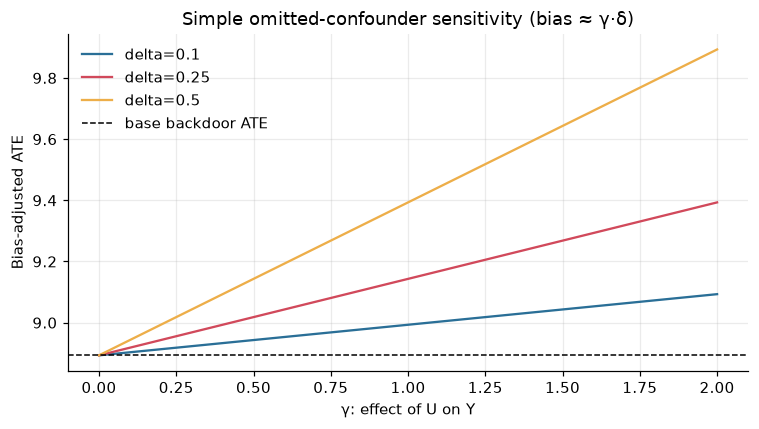

In [11]:
# Simple sensitivity: omitted-variable-bias style (linear) for one hypothetical confounder strength
# bias ≈ gamma * delta, where delta = effect of U on T (difference in means) and gamma = effect of U on Y
gammas = np.linspace(0, 2, 21)
deltas = [0.1, 0.25, 0.5]
base_ate = float(bd['ate'])
fig, ax = plt.subplots(figsize=(7,4))
for de in deltas:
    ax.plot(gammas, base_ate + gammas*de, label=f'delta={de}')
ax.axhline(base_ate, color='k', ls='--', lw=1, label='base backdoor ATE')
ax.set_title('Simple omitted-confounder sensitivity (bias ≈ γ·δ)'); ax.set_xlabel('γ: effect of U on Y'); ax.set_ylabel('Bias-adjusted ATE'); ax.legend()
fig.tight_layout(); nb.save_fig(fig, 'causal_sensitivity'); plt.show()


**How to read this / what it shows.** Stratified effects explore heterogeneity. Differences by country/age may reflect effect modification or instability in small strata; confidence intervals are omitted for simplicity in this quickstart.

## Quantitative summary


In [13]:
summary = est_table.copy()
summary['truth_ate'] = float(truth)
summary['estimator_source'] = 'project' if use_project else 'fallback'
summary


,estimator,ate,ci_low,ci_high,truth_ate,estimator_source
0,naive_diff_means_obs,8.910316,NaN,NaN,1.227688,project
1,backdoor_adjusted,8.893189,8.540972,9.245405,1.227688,project
2,doubly_robust_aipw,8.784276,8.329024,9.239527,1.227688,project
3,naive_diff_means_true,14.145657,NaN,NaN,1.227688,project
4,ground_truth_injected,1.227688,NaN,NaN,1.227688,project


## Sensitivity / ablation
- Adjustment set choice: missing confounders bias backdoor estimates; bad controls (colliders/mediators) can also bias.
- Overlap/positivity: extreme propensities inflate variance of IPW/DR.
- Model specification: DR helps if one nuisance model is adequate, but both wrong can still bias results.

## Limitations and failure cases
- Semi-synthetic injected truth validates mechanics on this dataset; it does not establish real-world causal claims.
- Unmeasured confounding is not ruled out by DAG validation alone.
- Light mode uses subsamples; intervals are approximate.

## Conclusions and further experiments
- DAG-informed adjustment and DR/AIPW were demonstrated and compared against injected truth.
- Propensity/balance diagnostics highlight identification assumptions in practice.
- Further work: refutation tests (placebo, random common cause), richer CATE models, and transport of causal effects across countries.

## References
- J. Pearl. *Causality: Models, Reasoning, and Inference*. Cambridge University Press, 2009.
- J. M. Robins, A. Rotnitzky, L. P. Zhao. "Estimation of Regression Coefficients When Some Regressors are not Always Observed." *JASA*, 1994.
- V. Chernozhukov et al. "Double/debiased machine learning for treatment and structural parameters." *The Econometrics Journal*, 2018.
